In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Libraries imported successfully!")

Libraries imported successfully!


Dataset created successfully!
Number of samples: 500
Number of features: 2


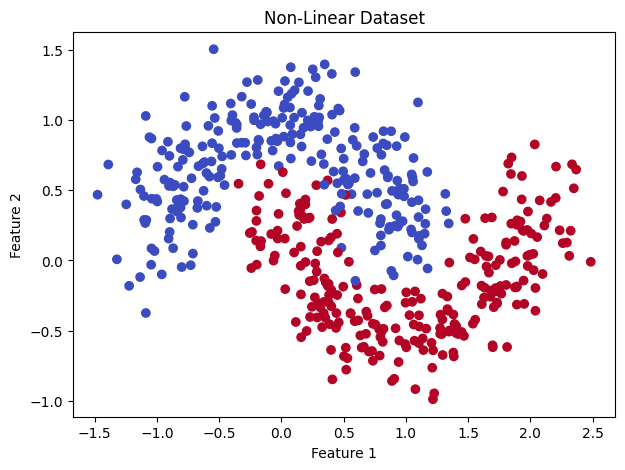

In [ ]:
# Generate non-linear dataset
X, y = make_moons(
    n_samples=500,
    noise=0.20,
    random_state=42
)

print("Dataset created successfully!")
print("Number of samples:", X.shape[0])
print("Number of features:", X.shape[1])

# Display the dataset
plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm")
plt.title("Non-Linear Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 400
Testing samples: 100


In [ ]:
# Create a Non-Linear SVM using the RBF kernel
model = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", C=1.0, gamma="scale")
)

# Train the model
model.fit(X_train, y_train)

print("Non-Linear SVM model trained successfully!")

Non-Linear SVM model trained successfully!


In [ ]:
# Predict test data
y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Model Accuracy: 99.0 %

Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99        50
           1       1.00      0.98      0.99        50

    accuracy                           0.99       100
   macro avg       0.99      0.99      0.99       100
weighted avg       0.99      0.99      0.99       100

Confusion Matrix:
[[50  0]
 [ 1 49]]


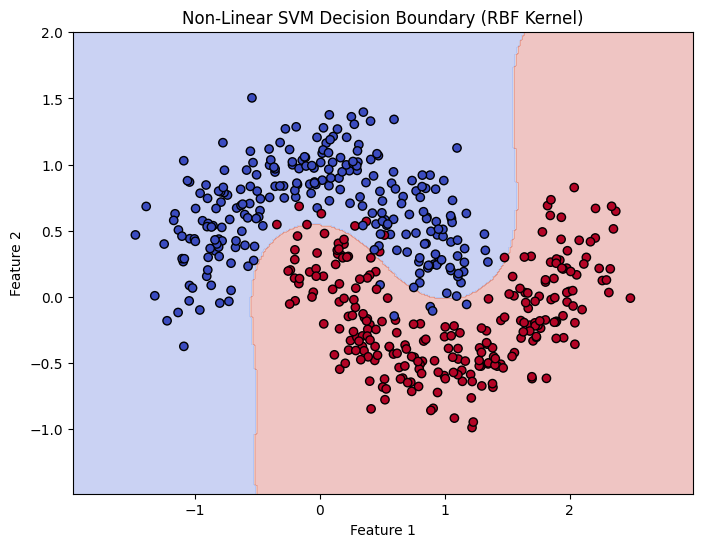

In [ ]:
# Create a grid of points
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

# Predict class for every grid point
grid = np.c_[xx.ravel(), yy.ravel()]
Z = model.predict(grid)
Z = Z.reshape(xx.shape)

# Plot decision boundary and data points
plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")
plt.scatter(
    X[:, 0], X[:, 1],
    c=y, cmap="coolwarm",
    edgecolors="black"
)

plt.title("Non-Linear SVM Decision Boundary (RBF Kernel)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

In [ ]:
# Test with a new sample
sample = [[0.5, 0.2]]

prediction = model.predict(sample)[0]

print("Input sample:", sample)

if prediction == 0:
    print("Predicted Class: Class 0")
else:
    print("Predicted Class: Class 1")

Input sample: [[0.5, 0.2]]
Predicted Class: Class 1


In [ ]:
# Train Linear SVM
linear_model = make_pipeline(
    StandardScaler(),
    SVC(kernel="linear")
)

linear_model.fit(X_train, y_train)

linear_pred = linear_model.predict(X_test)
nonlinear_pred = model.predict(X_test)

print("Linear SVM Accuracy:",
      round(accuracy_score(y_test, linear_pred) * 100, 2), "%")

print("Non-Linear SVM Accuracy:",
      round(accuracy_score(y_test, nonlinear_pred) * 100, 2), "%")

Linear SVM Accuracy: 86.0 %
Non-Linear SVM Accuracy: 99.0 %
